In [140]:
### imports
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from dotenv import load_dotenv


In [141]:
### load environment variables
load_dotenv()
# read in environment variables for file paths
airline_file_path = os.getenv("AIRLINE_FILE_PATH")
booking_file_path = os.getenv("BOOKING_FILE_PATH")

In [142]:
### read in datasets
airline_df = pd.read_csv(airline_file_path)
booking_df = pd.read_csv(booking_file_path)

### EDA and Data Cleaning

In [143]:
airline_df.info()

# Unique values in Start, End, and Route columns
print("Unique Start Locations:", airline_df['Start_Location'].nunique())
print("Unique End Locations:", airline_df['End_Location'].nunique())
print("Unique Routes:", airline_df['Route'].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3575 entries, 0 to 3574
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Passanger_Name   3574 non-null   object 
 1   Flying_Date      955 non-null    object 
 2   Route            2809 non-null   object 
 3   Rating           3575 non-null   int64  
 4   Verified         3575 non-null   object 
 5   Review_title     3575 non-null   object 
 6   Review_content   3575 non-null   object 
 7   Traveller_Type   3575 non-null   object 
 8   Class            3575 non-null   object 
 9   Start_Location   2809 non-null   object 
 10  End_Location     2809 non-null   object 
 11  Layover_Route    484 non-null    object 
 12  Start_Latitude   3515 non-null   float64
 13  Start_Longitude  3515 non-null   float64
 14  Start_Address    3515 non-null   object 
 15  End_Latitude     3476 non-null   float64
 16  End_Longitude    3476 non-null   float64
 17  End_Address   

In [ ]:
booking_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50002 entries, 0 to 50001
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50002 non-null  int64  
 1   sales_channel          50002 non-null  object 
 2   trip_type              50002 non-null  object 
 3   purchase_lead          50002 non-null  int64  
 4   length_of_stay         50002 non-null  int64  
 5   flight_hour            50002 non-null  int64  
 6   flight_day             50002 non-null  object 
 7   route                  50002 non-null  object 
 8   booking_origin         50002 non-null  object 
 9   wants_extra_baggage    50002 non-null  int64  
 10  wants_preferred_seat   50002 non-null  int64  
 11  wants_in_flight_meals  50002 non-null  int64  
 12  flight_duration        50002 non-null  float64
 13  booking_complete       50002 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

In [ ]:
# --- Analysis Code to Compare Start, End VS Route ---
analysis_df = pd.read_csv(airline_file_path)
analysis_df['satisfaction'] = (analysis_df['Rating'] >= 5).astype(int)

# Group by 'Route' and calculate average satisfaction
route_satisfaction = analysis_df.groupby('Route')['satisfaction'].count().sort_values(ascending=False)
print(route_satisfaction)
# Print how many are less than 50
print(f"Routes with less than 50 entries: {(route_satisfaction < 50).sum()}")

# Group by 'Start_Location' and calculate average satisfaction
start_satisfaction = analysis_df.groupby('Start_Location')['satisfaction'].count().sort_values(ascending=False)
print(start_satisfaction)
# Print how many are less than 50
print(f"Start Locations with less than 50 entries: {(start_satisfaction < 50).sum()}")

# Group by 'End_Location' and calculate average satisfaction
end_satisfaction = analysis_df.groupby('End_Location')['satisfaction'].count().sort_values(ascending=False)
print(end_satisfaction)
# Print how many are less than 50
print(f"End Locations with less than 50 entries: {(end_satisfaction < 50).sum()}")

Route
London to Johannesburg                    16
London to Cape Town                       15
Johannesburg to London                    13
BKK to LHR                                13
Vancouver to London                       13
                                          ..
Kuwait to Edinburgh via London             1
Kuala Lumpur to Miami via London           1
Kuala Lumpur to Mexico City via London     1
Kuala Lumpur to Madrid via London          1
lgw to alicante                            1
Name: satisfaction, Length: 1541, dtype: int64
Routes with less than 50 entries: 1541
Start_Location
London Heathrow                                583
London                                         498
London Gatwick                                 205
Glasgow                                         30
Manchester                                      29
                                              ... 
Madeira                                          1
Mahe                                     

In [145]:
### Feature Selection

## Passenger Name:
# Not many unique values
# Irrelevant for analysis, so it can be dropped.

## Flying Date:
# 2620 null are null values (2620/3575 = 73.3%). 
# We can drop this column as it has too many null values.

## Review Title:
# Review content is more detailed than the title.
# Not many are unique values.
# Plus, upon manual inspection, many titles just repeat the route, which can't be used for sentiment analysis.
# We can drop this column.

## Layover Route:
# 3091 null values (3091/3575 = 86.4%).
# We can drop this column as it has too many null values.

# Start_/End_ location strings, coordinates, and addresses are high-cardinality geospatial details
# that we are not engineering features from.
# Hence, we can drop these columns to keep the feature space compact.
# Encoding these high-cardinality categorical features would lead to a very sparse matrix,
# which is not ideal for model training.

### Kept Columns:
'Route', 'Rating', 'Verified', 'Review_Content', 'Traveller_Type', 'Class'
## Route:
# Route is not kept for model training
# There are a lot of unique routes (1541), which makes it less useful for training.
# The model would also struggle to generalize well on unseen routes.
# However, it is kept for analysis purposes.

## Rating:
# This is the target variable for the classification task.
# We will convert ratings into binary sentiment labels (satisfied/unsatisfied).

## Verified:
# Asked for explicitly in the milestone requirements.

## Review Content:
# This is the main text data for sentiment analysis.

## Traveller Type:
# Different traveller types may have different satisfaction levels.
## Class:
# Different travel classes may have different satisfaction levels.

airline_df.drop(columns=['Passanger_Name', 'Flying_Date', 'Review_title', 'Start_Location', 'End_Location', 'Layover_Route', 'Start_Latitude', 'Start_Longitude', 'Start_Address', 'End_Latitude', 'End_Longitude', 'End_Address'], inplace=True)


In [146]:
### check for missing values in airline_df
print(airline_df.isnull().sum())

Route             766
Rating              0
Verified            0
Review_content      0
Traveller_Type      0
Class               0
dtype: int64


In [147]:
### check for missing values in booking_df
print(booking_df.isnull().sum())

num_passengers           0
sales_channel            0
trip_type                0
purchase_lead            0
length_of_stay           0
flight_hour              0
flight_day               0
route                    0
booking_origin           0
wants_extra_baggage      0
wants_preferred_seat     0
wants_in_flight_meals    0
flight_duration          0
booking_complete         0
dtype: int64


In [148]:
### impute missing route values in airline_df with mode with "UNKNOWN", not dropping rows because these represent 766 out of 3,575 (~21%).
airline_df['Route'].fillna('UNKNOWN', inplace=True)
print(airline_df.isnull().sum())

Route             0
Rating            0
Verified          0
Review_content    0
Traveller_Type    0
Class             0
dtype: int64


C:\Users\georg\AppData\Local\Temp\ipykernel_6868\2841039320.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  airline_df['Route'].fillna('UNKNOWN', inplace=True)


In [149]:
### check for duplicates in airline_df
duplicates_in_airline = airline_df.duplicated().sum()
duplicates_in_airline

74

In [150]:
### check for duplicates in booking_df
duplicates_in_booking = booking_df.duplicated().sum()
duplicates_in_booking

719

In [151]:
### drop duplicates in airline_df
airline_df.drop_duplicates(inplace=True)
duplicates_in_airline = airline_df.duplicated().sum()
duplicates_in_airline

0

In [152]:
### drop duplicates in booking_df
booking_df.drop_duplicates(inplace=True)
duplicates_in_booking = booking_df.duplicated().sum()
duplicates_in_booking

0

### Sentiment Analysis

In [153]:
### install vaderSentiment
%pip install vaderSentiment

Note: you may need to restart the kernel to use updated packages.


In [154]:
### sentiment analysis
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()

In [155]:
### define function to get sentiment score, compound score ranges from -1 (most negative) to +1 (most positive)
def get_sentiment_score(text):
    return analyzer.polarity_scores(text)['compound']

In [156]:
### apply sentiment analysis to Review_content column and create new column sentiment_score
airline_df['sentiment_score'] = airline_df['Review_content'].apply(get_sentiment_score)
print("✅ Sentiment scores calculated and added to the 'sentiment_score' column.")

✅ Sentiment scores calculated and added to the 'sentiment_score' column.


In [157]:
### define function to classify sentiment based on compound score
def classify_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

In [158]:
### create new column Sentiment_Analysis based on sentiment_score, classifying as Positive, Negative, or Neutral
airline_df['Sentiment_Analysis'] = airline_df['sentiment_score'].apply(classify_sentiment)


Distribution of sentiments:
Sentiment_Analysis
Positive    2028
Negative    1433
Neutral       40
Name: count, dtype: int64


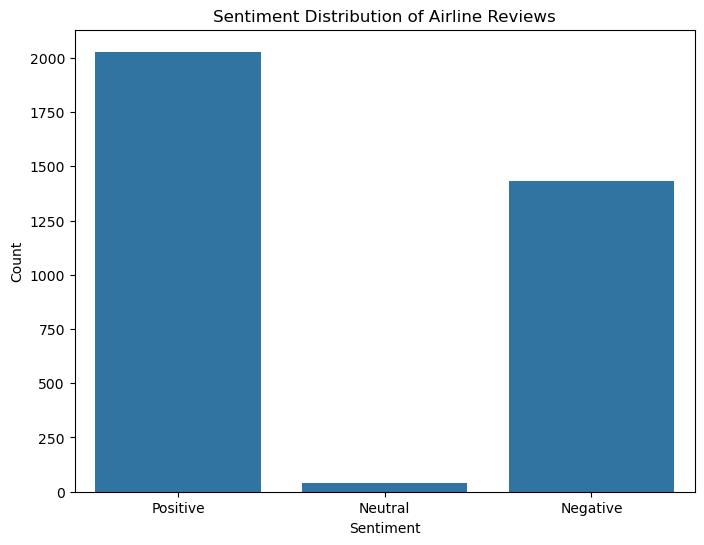

In [159]:
### display distribution of sentiments
print("\nDistribution of sentiments:")
print(airline_df['Sentiment_Analysis'].value_counts())

### visualize sentiment distribution
plt.figure(figsize=(8, 6))
sns.countplot(data=airline_df, x='Sentiment_Analysis', order=['Positive', 'Neutral', 'Negative'])
plt.title('Sentiment Distribution of Airline Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()

### Answering basic data engineering questions

In [160]:
### What are the top 10 most popular flight routes based on number of bookings? Used booking_df to answer the question
top_10_routes = booking_df['route'].value_counts()
top_10_routes = top_10_routes.head(10)
print(top_10_routes)

route
AKLKUL    2620
PENTPE     912
MELSGN     833
ICNSIN     793
DMKKIX     729
ICNSYD     683
DMKPER     677
DPSICN     658
DMKOOL     652
MELTPE     637
Name: count, dtype: int64


C:\Users\georg\AppData\Local\Temp\ipykernel_6868\4146583327.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_routes.index, y=top_10_routes.values, palette='viridis')


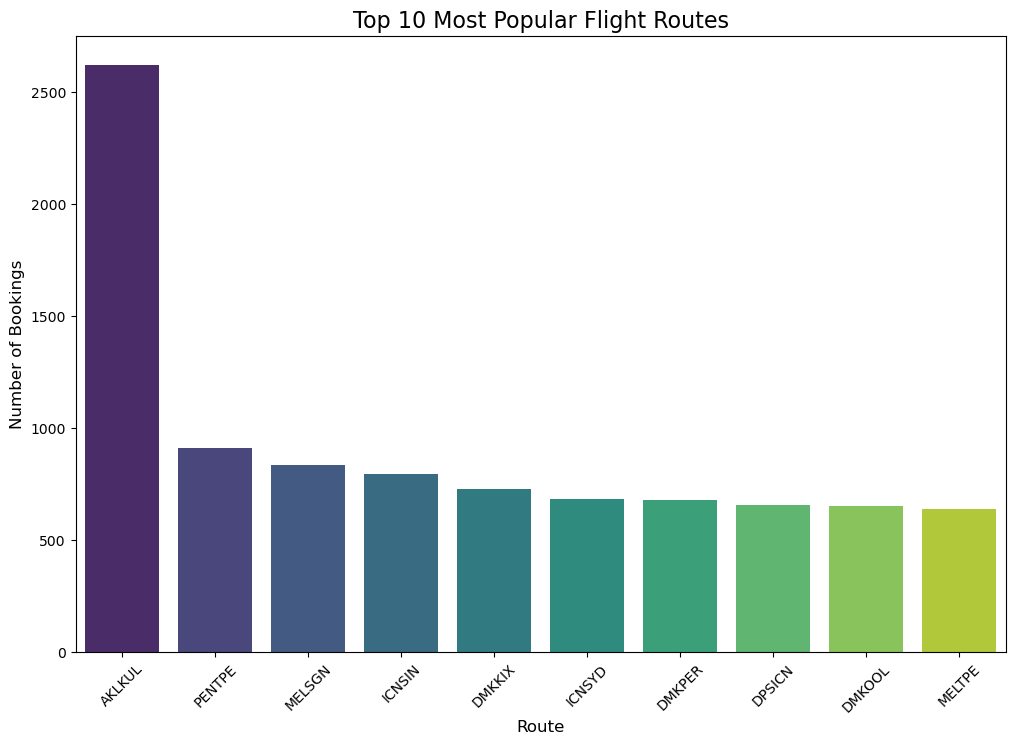

In [161]:
### visualize the results
plt.figure(figsize=(12, 8))
sns.barplot(x=top_10_routes.index, y=top_10_routes.values, palette='viridis')
plt.title('Top 10 Most Popular Flight Routes', fontsize=16)
plt.xlabel('Route', fontsize=12)
plt.ylabel('Number of Bookings', fontsize=12)
plt.xticks(rotation=45)
plt.show()

C:\Users\georg\AppData\Local\Temp\ipykernel_6868\3079594366.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='flight_hour', data=booking_df, palette='magma')


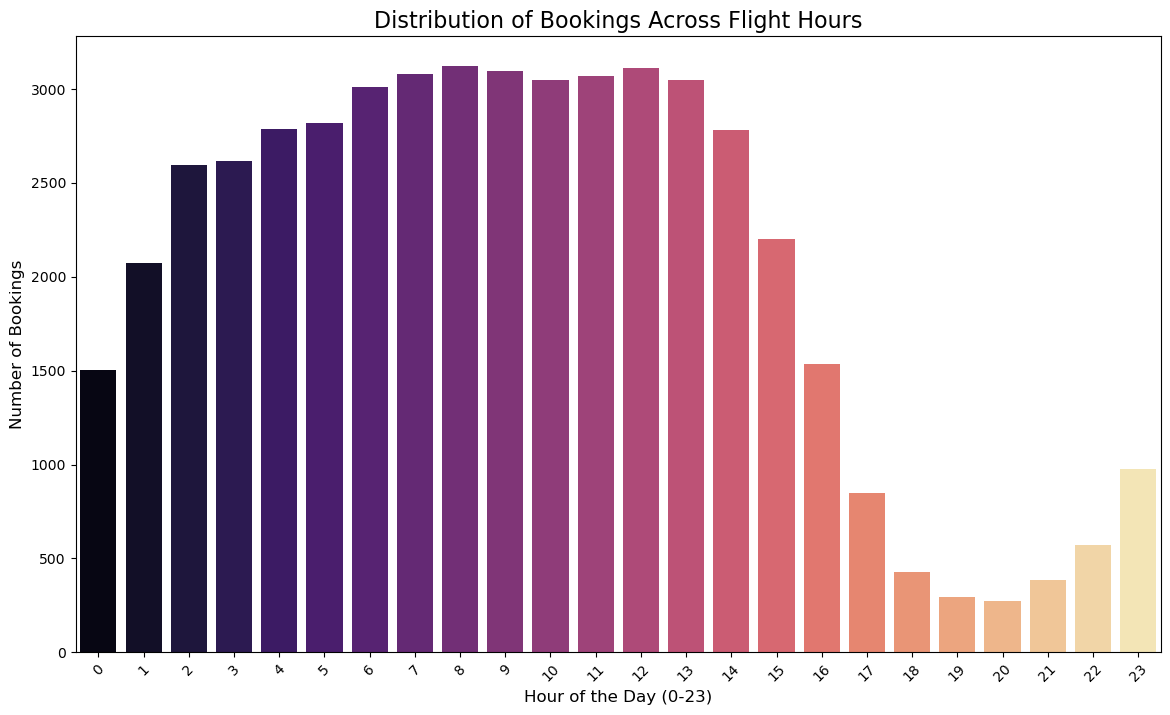


Number of bookings for each hour:
flight_hour
0     1501
1     2071
2     2596
3     2616
4     2786
5     2817
6     3011
7     3080
8     3125
9     3098
10    3050
11    3071
12    3114
13    3046
14    2783
15    2201
16    1536
17     848
18     430
19     294
20     275
21     386
22     573
23     975
Name: count, dtype: int64


In [162]:
### What is the distribution of bookings across different flight hours?

# set the figure size for better readability
plt.figure(figsize=(14, 8))

# create a count plot to show the number of bookings for each hour
sns.countplot(x='flight_hour', data=booking_df, palette='magma')

# add titles and labels for clarity
plt.title('Distribution of Bookings Across Flight Hours', fontsize=16)
plt.xlabel('Hour of the Day (0-23)', fontsize=12)
plt.ylabel('Number of Bookings', fontsize=12)
plt.xticks(rotation=45) # Rotate x-axis labels if they overlap

# display the plot
plt.show()

# you can also get the exact numbers using value_counts()
flight_hour_counts = booking_df['flight_hour'].value_counts().sort_index()
print("\nNumber of bookings for each hour:")
print(flight_hour_counts)

In [163]:
### How do average ratings vary by Traveller_Type and Class?
rating_by_group = airline_df.groupby(['Traveller_Type', 'Class']).agg(
    average_rating=('Rating', 'mean'),
    review_count=('Rating', 'size')
).reset_index()

# display the first few rows of the newly created summary DataFrame
print("Summary of Ratings by Group:")
rating_by_group.head()

Summary of Ratings by Group:


,Traveller_Type,Class,average_rating,review_count
0,Business,Business Class,3.510791,278
1,Business,Economy Class,3.457031,256
2,Business,First Class,4.270270,37
3,Business,Premium Economy,3.750000,52
4,Couple Leisure,Business Class,5.324324,333


In [164]:
### display the full sorted table to see the complete ranking
sorted_ratings = rating_by_group.sort_values(by='average_rating', ascending=False)

print("--- Average Ratings for Each Combination (Sorted Highest to Lowest) ---")
print(sorted_ratings)

--- Average Ratings for Each Combination (Sorted Highest to Lowest) ---
    Traveller_Type            Class  average_rating  review_count
19         Unknown      First Class        7.166667            48
14    Solo Leisure      First Class        6.627907            43
6   Couple Leisure      First Class        5.983607            61
20         Unknown  Premium Economy        5.948052            77
17         Unknown   Business Class        5.908046           261
18         Unknown    Economy Class        5.800664           301
12    Solo Leisure   Business Class        5.780347           173
8   Family Leisure   Business Class        5.743902            82
15    Solo Leisure  Premium Economy        5.653061            98
4   Couple Leisure   Business Class        5.324324           333
13    Solo Leisure    Economy Class        4.631193           545
2         Business      First Class        4.270270            37
10  Family Leisure      First Class        4.230769            13
7   

In [165]:
### get the first row for the highest rated combination
highest_rated = sorted_ratings.iloc[0]

### get the last row for the lowest rated combination
lowest_rated = sorted_ratings.iloc[-1]

print(f"✅ Highest Rated Combination: '{highest_rated['Traveller_Type']}' in '{highest_rated['Class']}' with an average rating of {highest_rated['average_rating']:.2f} from {highest_rated['review_count']} reviews.")
print(f"✅ Lowest Rated Combination:  '{lowest_rated['Traveller_Type']}' in '{lowest_rated['Class']}' with an average rating of {lowest_rated['average_rating']:.2f} from {lowest_rated['review_count']} reviews.")

✅ Highest Rated Combination: 'Unknown' in 'First Class' with an average rating of 7.17 from 48 reviews.
✅ Lowest Rated Combination:  'Various' in 'Economy Class' with an average rating of 1.00 from 1 reviews.


In [166]:
### pivot the data to create a matrix suitable for a heatmap
heatmap_data = sorted_ratings.pivot(index='Traveller_Type', columns='Class', values='average_rating')

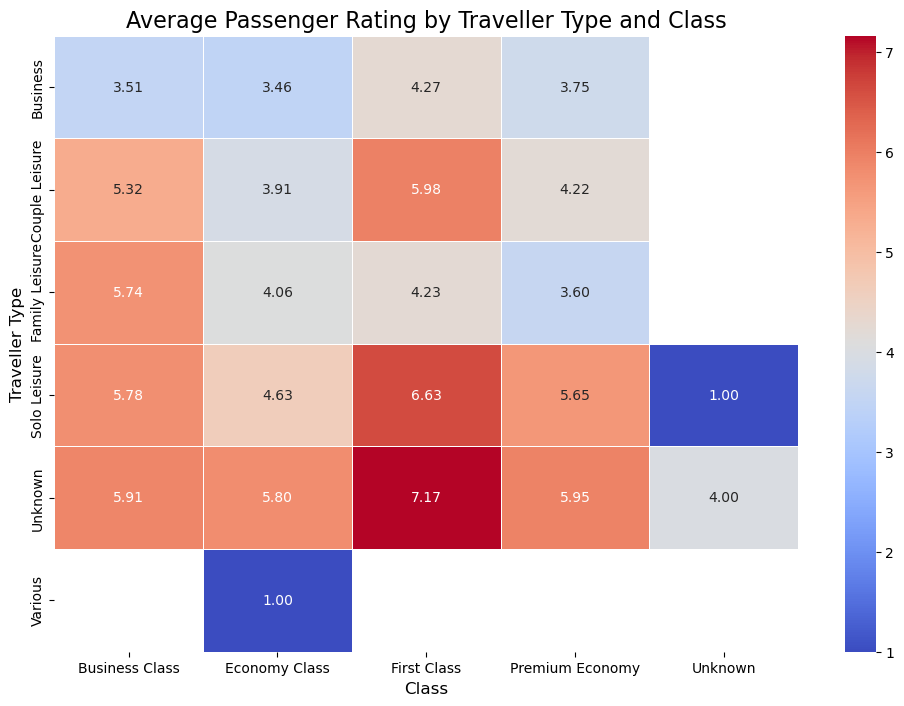

In [167]:
### display using a heatmap
# set the size of the figure
plt.figure(figsize=(12, 8))

# create the heatmap
sns.heatmap(
    heatmap_data,
    annot=True,      # Show the average rating numbers in the cells
    fmt=".2f",       # Format the numbers to two decimal places
    cmap='coolwarm', # Use a color map that shows high vs. low values clearly
    linewidths=.5    # Add lines between cells for better separation
)

# add titles and labels for clarity
plt.title('Average Passenger Rating by Traveller Type and Class', fontsize=16)
plt.xlabel('Class', fontsize=12)
plt.ylabel('Traveller Type', fontsize=12)

# display the plot
plt.show()

### Data preparation 

In [168]:
### threshold satisfaction column
airline_df['satisfaction'] = (airline_df['Rating'] >= 5).astype(int)
print(airline_df[['Rating', 'satisfaction']].head())

   Rating  satisfaction
0       1             0
1       1             0
2       2             0
3       4             0
4       7             1


In [169]:
### display the first few rows of airline_df to verify the new column
airline_df.head()

,Route,Rating,Verified,Review_content,Traveller_Type,Class,sentiment_score,Sentiment_Analysis,satisfaction
0,New Orleans to London,1,Trip Verified,The airline lost my luggage and was absolutely...,Solo Leisure,Economy Class,-0.7990,Negative,0
1,London to Amman,1,Trip Verified,"We booked on the BA website, round trip flight...",Couple Leisure,Business Class,0.0219,Neutral,0
2,Heathrow to Bodrum,2,Trip Verified,"First time flying with BA business class, neve...",Solo Leisure,Business Class,-0.7096,Negative,0
3,Amman to London,4,Not Verified,You can buy sandwiches and crisps but don't ex...,Solo Leisure,Economy Class,-0.5849,Negative,0
4,London City to Ibiza,7,Trip Verified,This is a two-for-one review covering economy ...,Family Leisure,Business Class,0.9789,Positive,1


In [170]:
### prepare features and target variable for prediction model
feature_columns = [
    'Traveller_Type',
    'Class',
    'Verified',
    'sentiment_score'
]

X = airline_df[feature_columns]
y = airline_df['satisfaction']

In [171]:
X.head()

,Traveller_Type,Class,Verified,sentiment_score
0,Solo Leisure,Economy Class,Trip Verified,-0.7990
1,Couple Leisure,Business Class,Trip Verified,0.0219
2,Solo Leisure,Business Class,Trip Verified,-0.7096
3,Solo Leisure,Economy Class,Not Verified,-0.5849
4,Family Leisure,Business Class,Trip Verified,0.9789


In [172]:
y.head()

0    0
1    0
2    0
3    0
4    1
Name: satisfaction, dtype: int32

In [173]:
X_processed = X.copy()

In [174]:
### define the mapping for the 'Verified' column
verified_map = {'Trip Verified': 1, 'Not Verified': 0}

### apply the mapping
X_processed['Verified'] = X_processed['Verified'].map(verified_map)

print("--- 'Verified' column after encoding ---")
print(X_processed['Verified'].value_counts())
print(X_processed.head())

--- 'Verified' column after encoding ---
Verified
0    2434
1    1067
Name: count, dtype: int64
   Traveller_Type           Class  Verified  sentiment_score
0    Solo Leisure   Economy Class         1          -0.7990
1  Couple Leisure  Business Class         1           0.0219
2    Solo Leisure  Business Class         1          -0.7096
3    Solo Leisure   Economy Class         0          -0.5849
4  Family Leisure  Business Class         1           0.9789


In [175]:
### define the explicit order for the 'Class' column
# we include 'Unknown' with the lowest value in case it appears.
class_map = {
    'Economy Class': 0,
    'Premium Economy': 1,
    'Business Class': 2,
    'First Class': 3,
    'Unknown': 0 # Treat 'Unknown' class same as Economy
}

### apply the mapping
X_processed['Class'] = X_processed['Class'].map(class_map)

print("\n--- 'Class' column after encoding ---")
print(X_processed['Class'].value_counts())
print(X_processed.head())


--- 'Class' column after encoding ---
Class
0    1825
2    1127
1     347
3     202
Name: count, dtype: int64
   Traveller_Type  Class  Verified  sentiment_score
0    Solo Leisure      0         1          -0.7990
1  Couple Leisure      2         1           0.0219
2    Solo Leisure      2         1          -0.7096
3    Solo Leisure      0         0          -0.5849
4  Family Leisure      2         1           0.9789


In [176]:
### One-Hot Encode the 'Traveller_Type' column
# 1. Initialize the OneHotEncoder
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# 2. Fit and transform the 'Traveller_Type' column
# We need to reshape the column to be 2D for the encoder
traveller_type_encoded = ohe.fit_transform(X_processed[['Traveller_Type']])

In [177]:
# The feature names are retrieved from the encoder
encoded_df = pd.DataFrame(traveller_type_encoded, columns=ohe.get_feature_names_out(['Traveller_Type']))

In [178]:
# Reset index of both dataframes to ensure they align correctly before merging
X_processed.reset_index(drop=True, inplace=True)
encoded_df.reset_index(drop=True, inplace=True)

In [179]:
X_processed = pd.concat([X_processed, encoded_df], axis=1)

In [180]:
X_processed.drop('Traveller_Type', axis=1, inplace=True)

In [181]:
print("\n--- Final Processed DataFrame (X_processed) ---")
print(X_processed.head())


--- Final Processed DataFrame (X_processed) ---
   Class  Verified  sentiment_score  Traveller_Type_Business  \
0      0         1          -0.7990                      0.0   
1      2         1           0.0219                      0.0   
2      2         1          -0.7096                      0.0   
3      0         0          -0.5849                      0.0   
4      2         1           0.9789                      0.0   

   Traveller_Type_Couple Leisure  Traveller_Type_Family Leisure  \
0                            0.0                            0.0   
1                            1.0                            0.0   
2                            0.0                            0.0   
3                            0.0                            0.0   
4                            0.0                            1.0   

   Traveller_Type_Solo Leisure  Traveller_Type_Unknown  Traveller_Type_Various  
0                          1.0                     0.0                     0.0  
1

<small><b>No standardization needed because most features are categorical and the only numerical feature (sentiment_score) already sits in a suitable range.</b></small>


In [182]:
### reusable preprocessing helpers
MODEL_DROP_COLUMNS = [
    'Passanger_Name', 'Flying_Date', 'Review_title',
    'Start_Location', 'End_Location', 'Layover_Route',
    'Start_Latitude', 'Start_Longitude', 'Start_Address',
    'End_Latitude', 'End_Longitude', 'End_Address'
]
MODEL_FEATURE_COLUMNS = X_processed.columns.tolist()

def drop_unused_columns(df: pd.DataFrame) -> pd.DataFrame:
    return df.drop(columns=[c for c in MODEL_DROP_COLUMNS if c in df.columns], errors='ignore')

def add_sentiment_features(df: pd.DataFrame) -> pd.DataFrame:
    work_df = df.copy()
    if 'sentiment_score' not in work_df.columns:
        if 'Review_content' not in work_df.columns:
            raise ValueError('Review_content column is required to derive sentiment_score.')
        work_df['sentiment_score'] = work_df['Review_content'].fillna('').apply(get_sentiment_score)
    return work_df

def encode_verified(df: pd.DataFrame) -> pd.DataFrame:
    work_df = df.copy()
    if 'Verified' not in work_df.columns:
        raise ValueError('Verified column is required for encoding.')
    work_df['Verified'] = work_df['Verified'].map(verified_map).fillna(0)
    return work_df

def encode_class(df: pd.DataFrame) -> pd.DataFrame:
    work_df = df.copy()
    if 'Class' not in work_df.columns:
        raise ValueError('Class column is required for encoding.')
    work_df['Class'] = work_df['Class'].map(class_map).fillna(0)
    return work_df

def encode_traveller_type(df: pd.DataFrame, encoder: OneHotEncoder, fit: bool = False) -> pd.DataFrame:
    work_df = df.copy()
    if 'Traveller_Type' not in work_df.columns:
        raise ValueError('Traveller_Type column is required for encoding.')
    if fit:
        encoded = encoder.fit_transform(work_df[['Traveller_Type']])
    else:
        encoded = encoder.transform(work_df[['Traveller_Type']])
    encoded_df = pd.DataFrame(
        encoded,
        columns=encoder.get_feature_names_out(['Traveller_Type']),
        index=work_df.index
    )
    work_df = pd.concat([work_df.drop(columns=['Traveller_Type']), encoded_df], axis=1)
    return work_df

def build_feature_matrix(df: pd.DataFrame, encoder: OneHotEncoder, fit: bool = False) -> pd.DataFrame:
    work_df = drop_unused_columns(df)
    work_df = add_sentiment_features(work_df)
    work_df = encode_verified(work_df)
    work_df = encode_class(work_df)
    work_df = encode_traveller_type(work_df, encoder=encoder, fit=fit)
    return work_df.loc[:, MODEL_FEATURE_COLUMNS]


In [183]:
### split the data into training and testing sets with stratification, stratification is basically ensuring that both training and testing sets have similar distribution of the target variable
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, 
    y, 
    test_size=0.2, 
    random_state=42,
    stratify=y
)

In [184]:
print("Data splitting complete.")
print(f"Shape of X_train (features for training): {X_train.shape}")
print(f"Shape of y_train (target for training):   {y_train.shape}")
print(f"Shape of X_test (features for testing):   {X_test.shape}")
print(f"Shape of y_test (target for testing):     {y_test.shape}")

Data splitting complete.
Shape of X_train (features for training): (2800, 9)
Shape of y_train (target for training):   (2800,)
Shape of X_test (features for testing):   (701, 9)
Shape of y_test (target for testing):     (701,)


### Models building and testing

In [185]:
### Test with logistic regression model
### class_weight='balanced' is used to handle class imbalance by adjusting weights inversely proportional to class frequencies, this helps the model pay more attention to the minority class during training.
model_lr = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)

In [186]:
print("Training the Logistic Regression model...")
model_lr.fit(X_train, y_train)
print("✅ Model training complete.")

Training the Logistic Regression model...
✅ Model training complete.


In [187]:
# 1. Use the trained model to make predictions on the test set.
y_pred_lr = model_lr.predict(X_test)

# 2. Calculate the overall accuracy.
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"--- Logistic Regression Model Performance ---")
print(f"Overall Accuracy: {accuracy_lr:.4f}\n")

# 3. Generate a detailed Classification Report.
#    This report includes precision, recall, and F1-score for each class.
print("Classification Report:")
print(classification_report(y_test, y_pred_lr, target_names=['Dissatisfied (0)', 'Satisfied (1)']))

--- Logistic Regression Model Performance ---
Overall Accuracy: 0.7903

Classification Report:
                  precision    recall  f1-score   support

Dissatisfied (0)       0.84      0.74      0.79       367
   Satisfied (1)       0.75      0.85      0.79       334

        accuracy                           0.79       701
       macro avg       0.79      0.79      0.79       701
    weighted avg       0.80      0.79      0.79       701



In [188]:
### Test with Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# --- Initialize and Train the Random Forest Model ---

# 1. Initialize the model.
#    - n_estimators=100 means we will build 100 decision trees.
#    - random_state=42 for reproducibility.
#    - class_weight='balanced_subsample' is a good practice for Random Forest to handle class imbalance.
model_rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced_subsample', n_jobs=-1)

# 2. Train the model on the same training data.
print("Training the Random Forest model...")
model_rf.fit(X_train, y_train)

print("✅ Model training complete.")

Training the Random Forest model...
✅ Model training complete.


In [189]:
# --- Make Predictions and Evaluate the Random Forest ---

# 1. Use the trained model to make predictions on the test set.
y_pred_rf = model_rf.predict(X_test)

# 2. Calculate the overall accuracy.
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"--- Random Forest Model Performance ---")
print(f"Overall Accuracy: {accuracy_rf:.4f}\n")

# 3. Generate a detailed Classification Report.
print("Classification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['Dissatisfied (0)', 'Satisfied (1)']))

--- Random Forest Model Performance ---
Overall Accuracy: 0.7689

Classification Report:
                  precision    recall  f1-score   support

Dissatisfied (0)       0.78      0.78      0.78       367
   Satisfied (1)       0.76      0.75      0.76       334

        accuracy                           0.77       701
       macro avg       0.77      0.77      0.77       701
    weighted avg       0.77      0.77      0.77       701



In [190]:
### Test with a deep learning model, using TensorFlow and Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.callbacks import EarlyStopping
# 1. Build the Neural Network model
model_dl = Sequential([
    layers.InputLayer(input_shape=(X_train.shape[1],)),  # Input layer matching the number of features
    layers.Dense(32, activation='relu'),                  # First hidden layer with 64 neurons
    layers.Dense(16, activation='relu'),                  # Second hidden layer with 32 neurons
    layers.Dense(1, activation='sigmoid')                 # Output layer for binary classification
])
# 2. Compile the model
model_dl.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', Precision(), Recall()]
)
print("Training the Deep Learning model...")
# 3. Train the model, with early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_accuracy', patience=3)
model_dl.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2, verbose=1, callbacks=[early_stopping])
print("✅ Model training complete.")

Training the Deep Learning model...
Epoch 1/20


c:\Users\georg\anaconda3\Lib\site-packages\keras\src\layers\core\input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7540 - loss: 0.5828 - precision_2: 0.6842 - recall_2: 0.8936 - val_accuracy: 0.8107 - val_loss: 0.5137 - val_precision_2: 0.7577 - val_recall_2: 0.9015
Epoch 2/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8004 - loss: 0.4887 - precision_2: 0.7556 - recall_2: 0.8559 - val_accuracy: 0.8143 - val_loss: 0.4486 - val_precision_2: 0.7760 - val_recall_2: 0.8723
Epoch 3/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8004 - loss: 0.4579 - precision_2: 0.7604 - recall_2: 0.8456 - val_accuracy: 0.8196 - val_loss: 0.4410 - val_precision_2: 0.7973 - val_recall_2: 0.8467
Epoch 4/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8031 - loss: 0.4517 - precision_2: 0.7670 - recall_2: 0.8399 - val_accuracy: 0.8161 - val_loss: 0.4373 - val_precision_2: 0.7938 - val_recall_2: 0.8431
Epoch 5/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8049 - loss: 0.4498 - precision_2: 0.7692 - recall_2: 0.8409 - val_accuracy: 0.8143

In [191]:
### Evaluate the Deep Learning model
# 1. Make predictions on the test set
y_pred_dl_prob = model_dl.predict(X_test)
# print(f"Predictions shape: {y_pred_dl_prob.shape}")
y_pred_dl = (y_pred_dl_prob >= 0.5).astype(int)
# print(f"y_pred_dl shape after thresholding: {y_pred_dl.shape}")
print(f"--- Deep Learning Model Performance ---")
# 2. Calculate the overall accuracy.
accuracy_dl = accuracy_score(y_test, y_pred_dl)
print(f"Overall Accuracy: {accuracy_dl:.4f}\n")
# 3. Generate a detailed Classification Report.
print("Classification Report:")
print(classification_report(y_test, y_pred_dl, target_names=['Dissatisfied (0)', 'Satisfied (1)']))

22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
--- Deep Learning Model Performance ---
Overall Accuracy: 0.7917

Classification Report:
                  precision    recall  f1-score   support

Dissatisfied (0)       0.83      0.76      0.79       367
   Satisfied (1)       0.76      0.83      0.79       334

        accuracy                           0.79       701
       macro avg       0.79      0.79      0.79       701
    weighted avg       0.79      0.79      0.79       701



### Model performance comparison


,accuracy,precision,recall,f1
model,,,,
Logistic Regression,0.7903,0.7467,0.8473,0.7938
Random Forest,0.7689,0.7590,0.7545,0.7568
Neural Network,0.7917,0.7582,0.8263,0.7908


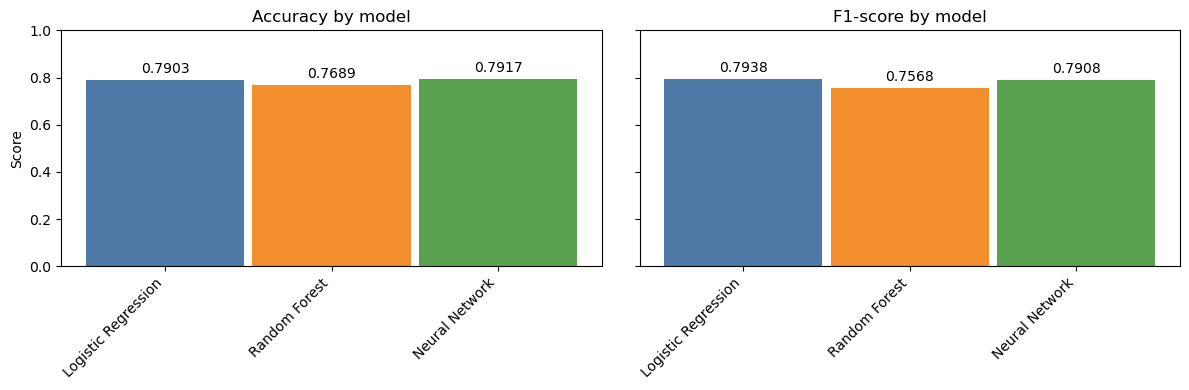

In [192]:
# Collect accuracy, precision, recall, and F1 for each trained model
from sklearn.metrics import precision_score, recall_score, f1_score

metrics_summary = pd.DataFrame([
    {
        'model': 'Logistic Regression',
        'accuracy': accuracy_lr,
        'precision': precision_score(y_test, y_pred_lr),
        'recall': recall_score(y_test, y_pred_lr),
        'f1': f1_score(y_test, y_pred_lr)
    },
    {
        'model': 'Random Forest',
        'accuracy': accuracy_rf,
        'precision': precision_score(y_test, y_pred_rf),
        'recall': recall_score(y_test, y_pred_rf),
        'f1': f1_score(y_test, y_pred_rf)
    },
    {
        'model': 'Neural Network',
        'accuracy': accuracy_dl,
        'precision': precision_score(y_test, y_pred_dl),
        'recall': recall_score(y_test, y_pred_dl),
        'f1': f1_score(y_test, y_pred_dl)
    }
]).set_index('model')

display(metrics_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
colors = ['#4e79a7', '#f28e2b', '#59a14f']
positions = range(len(metrics_summary))

accuracy_bars = axes[0].bar(positions, metrics_summary['accuracy'], width=0.95, color=colors)
axes[0].set_title('Accuracy by model')
axes[0].set_ylabel('Score')
axes[0].set_ylim(0, 1)
axes[0].set_xticks(list(positions))
axes[0].set_xticklabels(metrics_summary.index, rotation=45, ha='right')
axes[0].bar_label(accuracy_bars, fmt='%.4f', padding=3)

f1_bars = axes[1].bar(positions, metrics_summary['f1'], width=0.95, color=colors)
axes[1].set_title('F1-score by model')
axes[1].set_ylim(0, 1)
axes[1].set_xticks(list(positions))
axes[1].set_xticklabels(metrics_summary.index, rotation=45, ha='right')
axes[1].bar_label(f1_bars, fmt='%.4f', padding=3)

plt.tight_layout()
plt.show()


### Inference function and models inference speed comparison


In [193]:
import time

def _ensure_dataframe(raw_input) -> pd.DataFrame:
    if isinstance(raw_input, pd.DataFrame):
        return raw_input.copy()
    if isinstance(raw_input, pd.Series):
        return raw_input.to_frame().T
    if isinstance(raw_input, dict):
        return pd.DataFrame([raw_input])
    raise TypeError('raw_input must be a DataFrame, Series, or dict-like object.')

def run_inference(model, raw_input, encoder=ohe):
    raw_df = _ensure_dataframe(raw_input)
    start = time.perf_counter()
    features = build_feature_matrix(raw_df, encoder=encoder, fit=False)
    predictions = model.predict(features)
    elapsed = time.perf_counter() - start
    labels = ['Satisfied' if p >= 0.5 else 'Dissatisfied' for p in predictions]
    return labels, elapsed, features


In [194]:
# Example inference with logistic regression model
pred_labels, inf_time_lr, processed_sample = run_inference(model_lr, airline_df.iloc[[0]])
print(f'model prediction: {pred_labels[0]}')
print(f'model inference time: {inf_time_lr:.6f} seconds')


model prediction: Dissatisfied
model inference time: 0.006069 seconds


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


,elapsed_sec,per_sample_ms
model,,
Logistic Regression,0.004693,0.046935
Random Forest,0.021840,0.218397
Neural Network,0.064827,0.648272


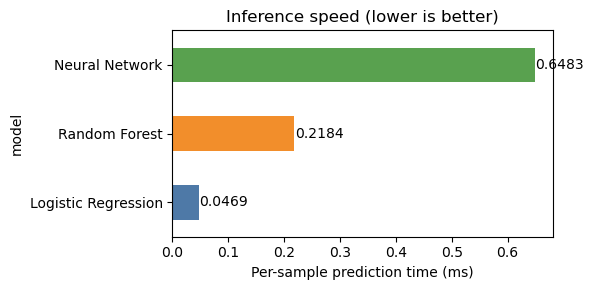

In [195]:
### define raw input sample as 100 random rows from airline_test_raw
sample_raw = airline_df.sample(n=100, random_state=42)

_, time_lr, _ = run_inference(model_lr, sample_raw)
_, time_rf, _ = run_inference(model_rf, sample_raw)
_, time_dl, _ = run_inference(model_dl, sample_raw)

n_samples = len(sample_raw)
inference_summary = pd.DataFrame([
    {'model': 'Logistic Regression', 'elapsed_sec': time_lr, 'per_sample_ms': (time_lr / n_samples) * 1000},
    {'model': 'Random Forest', 'elapsed_sec': time_rf, 'per_sample_ms': (time_rf / n_samples) * 1000},
    {'model': 'Neural Network', 'elapsed_sec': time_dl, 'per_sample_ms': (time_dl / n_samples) * 1000},
]).set_index('model')

display(inference_summary.round(6))

ax = inference_summary['per_sample_ms'].plot(kind='barh', color=['#4e79a7', '#f28e2b', '#59a14f'], figsize=(6, 3))
ax.set_xlabel('Per-sample prediction time (ms)')
ax.set_title('Inference speed (lower is better)')
for i, v in enumerate(inference_summary['per_sample_ms']):
    ax.text(v + 0.001, i, f'{v:.4f}', va='center')
plt.tight_layout()
plt.show()


<small>The best model in terms of Accuracy, F1 and inference speed is: <b>Logistic Regression</b>. Thus, it will be used as our model of choice</small>

### Model explainability

<small>We focus on explaining the <b>Logistic Regression</b> predictions because it is the overall best performer across accuracy, F1, and inference speed.</small>


In [302]:
%pip install shap

In [204]:
import shap

# --- Initialize the SHAP Explainer ---

# For linear models like Logistic Regression, we use the shap.LinearExplainer.
# It's highly optimized for this type of model.
# We pass it our trained model (model_lr) and the training data (X_train).
explainer = shap.LinearExplainer(model_lr, X_train)

# Calculate the SHAP values for the test set. 
# This tells us how each feature contributed to the prediction for each review in the test set.
shap_values = explainer.shap_values(X_test)

print("✅ SHAP explainer initialized and values calculated.")

✅ SHAP explainer initialized and values calculated.


--- Generating SHAP Summary Plot ---
This plot shows the most important features for the model.


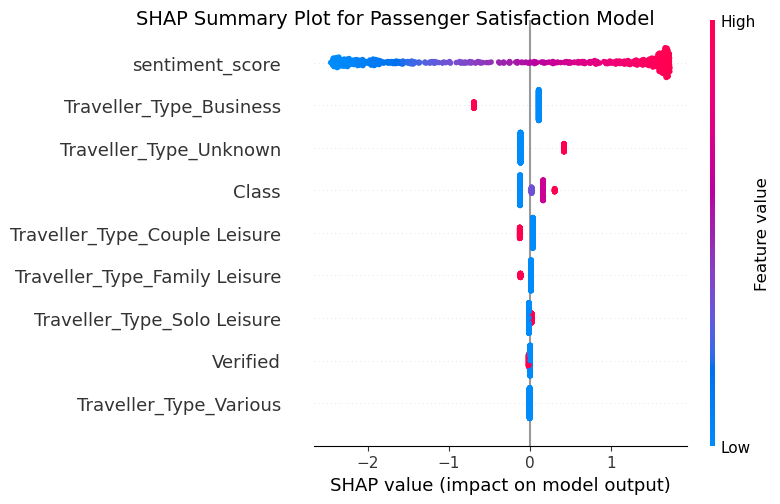

In [205]:
import shap
import matplotlib.pyplot as plt

# --- Create the SHAP Summary Plot ---

print("--- Generating SHAP Summary Plot ---")
print("This plot shows the most important features for the model.")

# Create the plot
shap.summary_plot(shap_values, X_test, show=False) # Use show=False to prevent auto-display

# Get a reference to the current figure and add the title
plt.gcf().suptitle("SHAP Summary Plot for Passenger Satisfaction Model", size=14)
plt.show() # Now display the completed plot

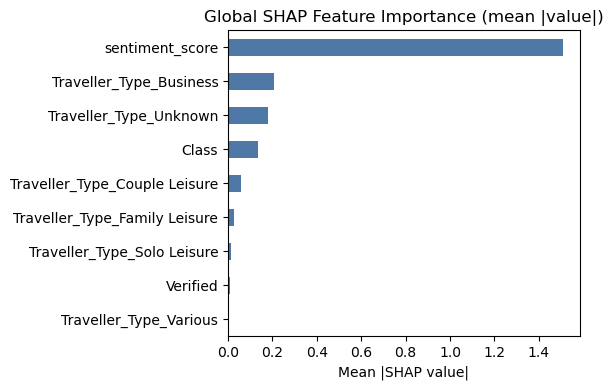

In [208]:
# Global feature importance using mean absolute SHAP values
import numpy as np
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=X_test.columns)
mean_abs_shap.sort_values(ascending=True).plot(kind='barh', figsize=(6, 4), color='#4e79a7')
plt.title('Global SHAP Feature Importance (mean |value|)')
plt.xlabel('Mean |SHAP value|')
plt.tight_layout()
plt.show()


#### Key Insights
- `sentiment_score` dominates, with high scores boosting and low scores lowering satisfaction.
- `Traveller_Type_Business` shows that when high (1), the traveler tends to be dissatisfied, and if not (0) tends to be slightly happier.
- `Traveller_Type_Unknown` show moderate positive influence when high (1), hinting they tend to be happier than business travelers.
- `Class` contributes positively at higher values, consistent with premium cabins improving satisfaction, for example first class (highest value) tends to be happier than the lowest value which is economy.
- Leisure traveler dummies (Couple, Family, Solo) exert smaller effects.
- `Verified` status barely moves predictions, indicating verification has little bearing on satisfaction.


In [206]:
import lime
import lime.lime_tabular

# --- Initialize the LIME Explainer ---

# LIME needs to understand the structure of your training data.
# We provide:
# - X_train.values: The numpy array of your training data.
# - feature_names: The column names of your processed features.
# - class_names: The names for your target variable (0 and 1).
# - mode='classification': To tell LIME this is a classification problem.

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=['Dissatisfied', 'Satisfied'],
    mode='classification'
)

print("✅ LIME explainer initialized successfully.")

✅ LIME explainer initialized successfully.


In [210]:
import numpy as np

# Find the index of a passenger that was ACTUALLY Dissatisfied (0) and PREDICTED Dissatisfied (0)
correctly_dissatisfied_idx = np.where((y_test == 0) & (y_pred_lr == 0))[0][0]

# Find the index of a passenger that was ACTUALLY Satisfied (1) and PREDICTED Satisfied (1)
correctly_satisfied_idx = np.where((y_test == 1) & (y_pred_lr == 1))[0][0]

print(f"We will explain the prediction for test set passenger at index: {correctly_dissatisfied_idx} (Dissatisfied)")
print(f"We will also explain the prediction for test set passenger at index: {correctly_satisfied_idx} (Satisfied)")

We will explain the prediction for test set passenger at index: 1 (Dissatisfied)
We will also explain the prediction for test set passenger at index: 0 (Satisfied)


In [ ]:
import pandas as pd

# This function takes a numpy array from LIME, converts it back to a DataFrame 
# with the correct column names, and then gets the prediction from our model.
def predict_fn_wrapper(x):
    x_df = pd.DataFrame(x, columns=X_train.columns)
    return model_lr.predict_proba(x_df)

print("✅ LIME helper function created.")

✅ LIME helper function created.


In [ ]:
# --- Generate LIME explanation for the DISSATISFIED passenger ---

instance_dissatisfied = X_test.iloc[correctly_dissatisfied_idx].values

# Use the NEW wrapper function here
explanation_dissatisfied = lime_explainer.explain_instance(
    instance_dissatisfied,
    predict_fn_wrapper,
)

print(f"\n--- LIME Explanation for Dissatisfied Passenger (Index: {correctly_dissatisfied_idx}) ---")
explanation_dissatisfied.show_in_notebook(show_table=True)


--- LIME Explanation for Dissatisfied Passenger (Index: 1) ---


In [ ]:
# --- Generate LIME explanation for the SATISFIED passenger ---

instance_satisfied = X_test.iloc[correctly_satisfied_idx].values

# Use the NEW wrapper function here
explanation_satisfied = lime_explainer.explain_instance(
    instance_satisfied,
    predict_fn_wrapper,
)

print(f"\n--- LIME Explanation for Satisfied Passenger (Index: {correctly_satisfied_idx}) ---")
explanation_satisfied.show_in_notebook(show_table=True)


--- LIME Explanation for Satisfied Passenger (Index: 0) ---


#### Key Insights
##### LIME explanations seem to agree with SHAP
- `sentiment_score` dominates, with the largest impact on prediction, as well.
- `Traveller_Type_Business` shows that when low, the traveler tends to be satisfied.
- `Traveller_Type_Unknown` shows slight negative influence when low, which agrees with SHAP values, as well.
- `Class` shows slight negative influence when low (economy).
- Leisure traveler dummies (Couple, Family, Solo) exert negligible influence.
- `Verified` status is discarded for having no notable influence.
